### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Final Exam [65 points total]

### Due: Tuesday, 24 November, 2026, 11:59 pm. NO EXTENSIONS, NO SUBMISSION ACCEPTED PAST DUE DATE/TIME.
---

## Problem 1 [30 points total]

One of the most important revelations in modern cosmology was the accelerated expansion of the Universe, interpreted as being caused by a non-zero Cosmological Constant. In this question you will use a simulated sample of Type Ia supernovae to infer the composition of the Universe. 

1. Load in `astr8070_final_cosmodata.npy`, which can be found in the Github repo under `coursework/final/final_data`. The first column is the SN redshift, the second is the distance modulus, and the third is the Gaussian uncertainty on this distance modulus. Make a labeled scatter plot of the data. [2 points]


2. Plot a line on top of this showing the relationship between the distance modulus and the redshift for the current concordance cosmology. You will need to look up the definition of the distance modulus, look up current reasonable cosmological parameters (cite your source), and plot the relationship. *Hint: check astropy.* [3 points]


3. Create a log-likelihood function that reads in the data and accepts values for the Hubble constant, $H_0$, and the fractional energy density in matter, $\Omega_M$. Assume a flat cosmological geometry, such that $\Omega_M + \Omega_\Lambda=1$. Your function should take $H_0$ and $\Omega_M$, and create a model for the distance moduli values at the redshifts of the samples, then compute the log-likelihood for the data. Print out the log-likelihood value at the cosmological parameter values that you used in (2). For maximum points, make sure your log-likelihood function is vectorized over the data samples. [6 points]


4. Perform an MCMC with appropriate diagnostic checks (either manually yourself, or fine if performed by the sampler you employ) over the $\{H_0, \Omega_M\}$ parameter space. Assume priors of $H_0 \in U[50,100]$ km.s$^{-1}$.Mpc$^{-1}$, and $\Omega_M \in U[0,1]$. Make a labeled corner plot showing the $1$D and $2$D marginalized posterior probability distribution of these parameters. State the median value of the $1$D marginal posteriors for each, along with the values enclosing the $68\%$ credible region. [8 points]


5. Draw $100$ random samples from your posterior chain and plot the corresponding band of solutions that are consistent with the data on the distance-modulus--vs--redshift plot along with the original data. [4 points]


6. Now, using an appropriate technique, find the Bayesian log-evidence of your $\{H_0,\Omega_M\}$ model above. Also find the log-evidence of a model with $\Omega_M=1$ such that $H_0$ is the only varied parameter. What is the Bayes factor for the presence of a Cosmological Constant given these data? [7 points] 

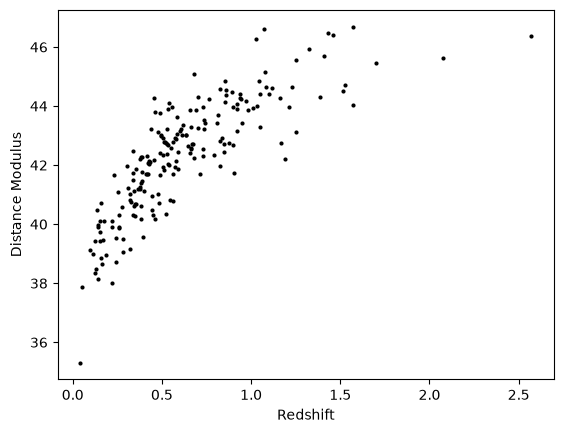

In [2]:
#Part1

import numpy as np
import matplotlib.pyplot as plt

data = np.load('final_data/astr8070_final_cosmodata.npy')

z = data[:,0]
mu = data[:,1]
sigma_mu = data[:,2]

plt.scatter(z, mu, s=9, lw=0, c='k')
plt.xlabel('Redshift')
plt.ylabel('Distance Modulus')
plt.show()

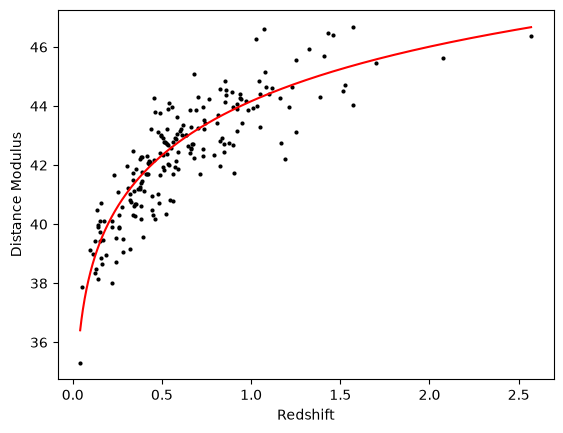

In [3]:
#Part2

from astropy.cosmology import FlatLambdaCDM

# Cosmological Parameters from Cortes et al. (2026), table 25.1
# https://arxiv.org/pdf/2602.13523

H0 = 67.4
Om = 0.315

# Cosmological model and distance modulus
# https://docs.astropy.org/en/stable/api/astropy.cosmology.FlatLambdaCDM.html

cosmo = FlatLambdaCDM(H0=H0, Om0=Om)
z_fit = np.linspace(min(z), max(z), 1000)
mu_fit = cosmo.distmod(z_fit).value

plt.scatter(z, mu, s=9, lw=0, c='k')
plt.plot(z_fit, mu_fit, '-r')
plt.xlabel('Redshift')
plt.ylabel('Distance Modulus')
plt.show()

In [4]:
#Part3
from scipy import stats

def Likelihood(H0, Om):
    cosmo = FlatLambdaCDM(H0=H0, Om0=Om)
    mu_model = cosmo.distmod(z).value

    #Gaussian model
    return np.prod(stats.norm(loc=mu_model, scale=sigma_mu).pdf(mu))

def Loglikelihood(H0, Om):
    return np.log(Likelihood(H0, Om))

print(Loglikelihood(H0, Om))

-268.1420089351839


done


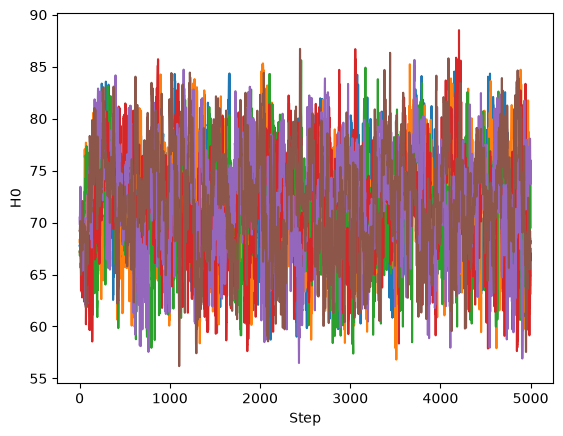

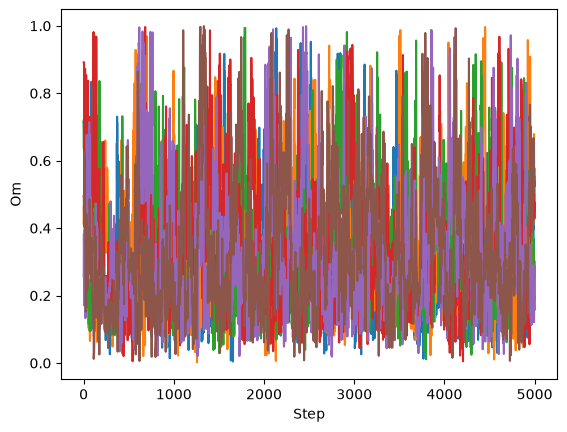

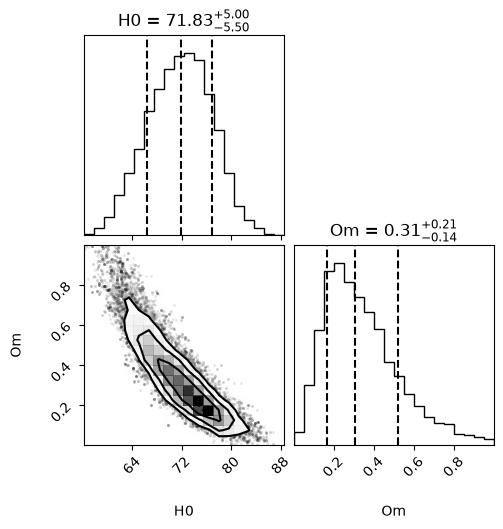

In [20]:
#Part 4
import emcee
import corner

#Define Priors

def Prior(x):
    prior_H0 = stats.uniform.pdf(x[0], loc=50, scale=50)
    prior_Om = stats.uniform.pdf(x[1], loc=0, scale=1)
    return prior_H0 * prior_Om

def logPrior(x):
    return np.log(Prior(x))

#define posterior
def myLogPosterior(x):
    if Prior(x) == 0:
        return -np.inf
    return Loglikelihood(x[0], x[1]) + logPrior(x)

#parameters
ndim = 2
nwalkers = 6
burn = 1000
nsteps = 5000

#initialize
np.random.seed(0)
starting_guesses = np.random.random((nwalkers, ndim))
starting_guesses[:,0] = 65 + 5*starting_guesses[:,0]

#run MCMC
sampler = emcee.EnsembleSampler(nwalkers, ndim, myLogPosterior)
sampler.run_mcmc(starting_guesses, nsteps)

#remove burn in
emcee_trace = sampler.chain[:,burn:,:].reshape(-1,ndim)
print("done")

#trace plots
xgrid = np.linspace( 1, nsteps, nsteps)

plt.figure()
for i in range(nwalkers):
    plt.plot(xgrid, sampler.chain[i,:,0])
plt.xlabel('Step')
plt.ylabel('H0')
plt.show()

plt.figure()
for i in range(nwalkers):
    plt.plot(xgrid, sampler.chain[i,:,1])
plt.xlabel('Step')
plt.ylabel('Om')
plt.show()

#corner plot
corner.corner(emcee_trace, labels=['H0', 'Om'], quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.show()

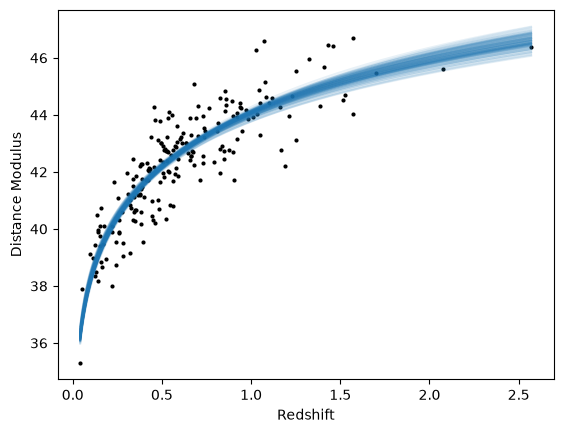

In [22]:
#part5
#100 draws
np.random.seed(0)
N = 100
indicies = np.random.randint(len(emcee_trace), size=N)

#plot
plt.figure()

for i in indicies:
    H0_sample = emcee_trace[i,0]
    Om_sample = emcee_trace[i,1]

    cosmo_sample = FlatLambdaCDM(H0=H0_sample, Om0=Om_sample)
    mu_sample = cosmo_sample.distmod(z_fit).value
    plt.plot(z_fit, mu_sample, color='C0', alpha=0.1)

#plot original data
plt.scatter(z, mu, s=9, lw=0, c='k')
plt.xlabel('Redshift')
plt.ylabel('Distance Modulus')
plt.show()

In [7]:
#part6
import dynesty

#Model 1: both H0 and Om as free params
def loglike1(x):
    return Loglikelihood(x[0], x[1])

def ptform1(u):
    params = u.copy()
    params[0] = u[0] * (100-50) + 50
    params[1] = u[1]
    return params

ndim = 2

sampler1 = dynesty.NestedSampler(loglike1, ptform1, ndim)
sampler1.run_nested()
sresults1 = sampler1.results

logZ1 = sresults1.logz[-1]
print("Model 1 log:", logZ1)

#Model 2: H0 free with Om=1
def loglike2(x):
    return Loglikelihood(x[0], 1)

def ptform2(u):
    params = u.copy()
    params[0] = u[0] * (100 - 50) + 50
    return params

ndim = 1

sampler2 = dynesty.NestedSampler(loglike2, ptform2, ndim)
sampler2.run_nested()
sresults2 = sampler2.results

logZ2 = sresults2.logz[-1]
print("Model 2 log", logZ2)

#Bayes factor
B = np.exp(logZ1 - logZ2)
print("Bayes factor:", B)

100%|█████████▉| 1964/1965 [05:02<00:00,  6.50it/s, +500 | bound: 1 | nc: 1 | ncall: 18619 | eff(%): 13.599 | loglstar: -266.229 | logz: -269.313 +/-  0.064 | dlogz:  0.001 >  0.509]


Model 1 log: -269.3133263777966


100%|█████████▉| 1637/1638 [04:45<00:00,  5.72it/s, +500 | bound: 0 | nc: 1 | ncall: 13924 | eff(%): 15.919 | loglstar: -269.786 | logz: -272.152 +/-  0.041 | dlogz:  0.001 >  0.509]

Model 2 log -272.1524145547772
Bayes factor: 17.10016610117711


## Problem 2 [35 points total]

There are several empirical scaling relationships between the masses of black holes in galaxy centers and the properties of their hosts. In this problem you will use real data from the "MASSIVE" Galaxy Survey. This data updates that used in [McConnell & Ma (2013)](https://ui.adsabs.harvard.edu/abs/2013ApJ...764..184M/abstract), which presented a systematic investigation of scaling relations with different catalog subsets.

1. Download this dataset: http://blackhole.berkeley.edu/wp-content/uploads/2016/09/current_ascii.txt. Skip the appropriate header rows and read this into a `pandas` dataframe. Use the meta-data in the header rows to create appropriate column names for your dataframe. Make sure that your data file is properly formatted with tab-spaced columns so that it is readable without errors. [3 points]


2. Create a data matrix out of the base-10 log values of: the galaxy distance, the velocity dispersion $\sigma$, and the black hole mass. Create a target vector that has $1$ for early-type galaxies (morphology has `E` or `S0` in the value) and $0$ for late-type galaxies. Print out the number of early-type and late-type galaxies that are in your target vector, as well as the total number of galaxies. [3 points]


3. Perform a 50-50 train-test split on the data matrix and target vector, using `random_state=0` for reproducibility. Train the following classifiers, overplotting ROC curves for all:
    - Gaussian Naive Bayes
    - LDA
    - QDA
    - $K$-nearest neighbors (with $K=10$)
    - Gaussian mixture model (with $2$ components)
    - Decision Tree (with `entropy` criterion, and tree depth $=2$)
 [5 points]
    

4. What minimum tree depth do you need to achieve essentially perfect classification accuracy with the Decision Tree? Confirm this by making a two-panel figure with scatter plots of the log10-distance and log10-sigma from the test data, color-coded by the test label (left panel) and predicted label (right panel).  [3 points]


5. The following regression tasks should all produce best-fit regression coefficients and a plot. State how many galaxies are being fit in each scenario.
    - Use the $68\%$ low and high black-hole mass values to deduce the uncertainty on each $(M_\mathrm{BH}/M_\odot)$. Convert this into an uncertainty on $\log_{10}(M_\mathrm{BH}/M_\odot)$. Ignoring the uncertainties on $\sigma$, perform linear regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$$
and state the best-fit regression coefficients $\{\alpha,\beta\}$. Plot the best-fit line on a scatter plot with the data. 
    - Repeat the previous bullet to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(L_V \,/\, 10^{11}L_\odot)$$ for the sub-sample of galaxies with $V$-band luminosity data (ignoring the $L_V$ uncertainties).
    - Repeat to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(M_\mathrm{bulge} \,/\, 10^{11}M_\odot)$$ for the sub-sample of galaxies with bulge mass measurements (ignoring the $M_\mathrm{bulge}$ uncertainties).
 [7 points]
 
 
6. Perform polynomial regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \sum_{p=1}^{N_p}\beta_p[\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})]^p.$$
For $N_p$ in the range $0$ to $5$, fit the polynomial relationship, print the regression coefficients, and compute the BIC value. Make a labeled plot of the BIC versus the polynomial degree. Is a quadratic or higher polynomial relationship between $\log_{10}(M_\mathrm{BH}/M_\odot)$ and $\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$ favored? [5 points]


7. Perform linear regression ($N_p=1$) on the dataset on sub-samples of early-type and late-type galaxies. Print the best-fit regression coefficients from each of these sub-sets. Make a scatter plot that includes the original data color coded by early/late type, the fit to all of the data, and the fits from the early/late-type sub-samples. The plot should have appropriate labels and a legend. [4 points]

In [12]:
#Part1
import pandas as pd

#data
columns = ['Galaxy', 'Distance', 'MBH', 'MBH_lower', 'MBH_upper', 'Method', 
           'sigma', 'sigma_lower', 'sigma_upper', 'logLV', 'logLV_error', 'logL36', 'logL36_error', 
           'Mbulge', 'Radius', 'Morphology', 'Profile', 'Reff_V', 'Reff_i', 'Reff_36']
df = pd.read_csv('final_data/astr8070_final_mcma.txt',
                 sep='\t', skiprows=25, names=columns, usecols=range(20))
#store
df

#pd.read_csv found in introduction to pandas section of python data science handbook put in lecture 1b

,Galaxy,Distance,MBH,MBH_lower,MBH_upper,Method,sigma,sigma_lower,sigma_upper,logLV,logLV_error,logL36,logL36_error,Mbulge,Radius,Morphology,Profile,Reff_V,Reff_i,Reff_36
0,MW,0.008,4.100000e+06,3.500000e+06,4.700000e+06,star,103.0,83.0,123.0,0.00,0.00,0.00,0.00,0.000000e+00,43.00,S,NaN,0.0,0.00,0.00
1,A1836,157.500,3.900000e+09,3.300000e+09,4.300000e+09,gas,288.0,274.0,302.0,11.26,0.06,0.00,0.00,0.000000e+00,0.27,E,C,0.0,17.61,0.00
2,A3565,54.400,1.400000e+09,1.200000e+09,1.700000e+09,gas,322.0,306.0,338.0,11.24,0.06,0.00,0.00,0.000000e+00,0.22,E,C,0.0,0.00,0.00
3,Circ,4.000,1.700000e+06,1.400000e+06,2.100000e+06,maser,158.0,140.0,176.0,0.00,0.00,10.31,0.02,0.000000e+00,0.02,S,NaN,0.0,0.00,10.83
4,IC1459,30.900,2.700000e+09,2.300000e+09,3.000000e+09,star,315.0,299.0,331.0,10.96,0.06,11.82,0.12,3.070000e+11,0.81,E,C,29.8,0.00,61.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,N7052,70.900,4.000000e+08,2.400000e+08,6.800000e+08,gas,266.0,253.0,279.0,10.92,0.04,11.82,0.06,3.500000e+11,0.07,E,C,40.5,0.00,39.30
74,N7582,22.300,5.500000e+07,4.400000e+07,7.100000e+07,gas,156.0,137.0,175.0,0.00,0.00,11.06,0.18,0.000000e+00,0.09,S,NaN,0.0,0.00,86.40
75,N7619,53.900,2.600000e+09,2.300000e+09,3.500000e+09,star,313.0,297.0,329.0,11.07,0.05,0.00,0.00,0.000000e+00,0.44,E,C,34.3,0.00,0.00
76,N7768,112.800,1.300000e+09,9.000000e+08,1.800000e+09,star,257.0,244.0,270.0,11.09,0.05,0.00,0.00,1.160000e+12,0.14,E,C,0.0,0.00,0.00


In [17]:
#part2
#create matrix
X = np.zeros((len(df), 3))
X[:,0] = np.log10(df['Distance'])
X[:,1] = np.log10(df['sigma'])
X[:,2] = np.log10(df['MBH'])

#target vector
y = np.zeros(len(df))

for i in range(len(df)):
    if 'E' in df['Morphology'][i] or 'S0' in df['Morphology'][i]:
        y[i] = 1

print("Early type galaxies:", np.sum(y == 1))
print("Late type galaxies:", np.sum(y == 0))
print("Total galaxies:", len(y))

Early type galaxies: 59
Late type galaxies: 19
Total galaxies: 78


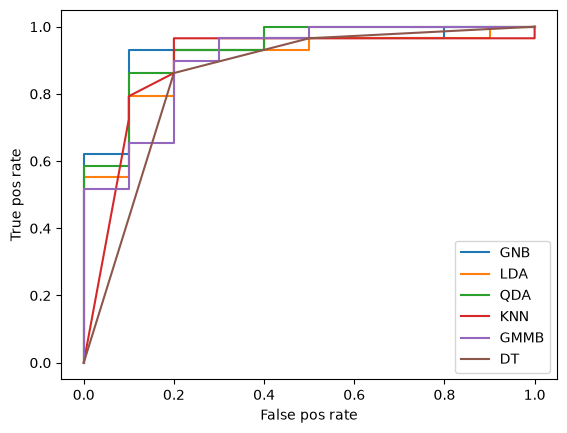

In [18]:
#part3
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from astroML.classification import GMMBayes
from sklearn.metrics import roc_curve

#train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

#classifiers
classifiers = [GaussianNB(), LinearDiscriminantAnalysis(), QuadraticDiscriminantAnalysis(),
               KNeighborsClassifier(n_neighbors=10), GMMBayes(n_components=2, tol=1E-5, covariance_type='full'),
               DecisionTreeClassifier(random_state=0, max_depth=2, criterion='entropy')]
labels = ['GNB', 'LDA', 'QDA', 'KNN', 'GMMB', 'DT']

#Fit and plot ROC
plt.figure()
for clf, name in zip(classifiers, labels):
    clf.fit(X_train, y_train)
    y_prob = clf.predict_proba(X_test)[:,1]
    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.xlabel('False pos rate')
plt.ylabel('True pos rate')
plt.legend()
plt.show()

In [21]:
#Part4
#prediction using classification accuracy
from sklearn.metrics import accuracy_score

for depth in range(1, len(X_train)):
    clf = DecisionTreeClassifier(random_state=0, max_depth=depth, criterion='entropy')
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print("Depth:", depth, "Accuracy:", accuracy_score(y_test, y_pred))

Depth: 1 Accuracy: 0.8461538461538461
Depth: 2 Accuracy: 0.8461538461538461
Depth: 3 Accuracy: 0.8461538461538461
Depth: 4 Accuracy: 0.8461538461538461
Depth: 5 Accuracy: 0.8717948717948718
Depth: 6 Accuracy: 0.8717948717948718
Depth: 7 Accuracy: 0.8717948717948718
Depth: 8 Accuracy: 0.8717948717948718
Depth: 9 Accuracy: 0.8717948717948718
Depth: 10 Accuracy: 0.8717948717948718
Depth: 11 Accuracy: 0.8717948717948718
Depth: 12 Accuracy: 0.8717948717948718
Depth: 13 Accuracy: 0.8717948717948718
Depth: 14 Accuracy: 0.8717948717948718
Depth: 15 Accuracy: 0.8717948717948718
Depth: 16 Accuracy: 0.8717948717948718
Depth: 17 Accuracy: 0.8717948717948718
Depth: 18 Accuracy: 0.8717948717948718
Depth: 19 Accuracy: 0.8717948717948718
Depth: 20 Accuracy: 0.8717948717948718
Depth: 21 Accuracy: 0.8717948717948718
Depth: 22 Accuracy: 0.8717948717948718
Depth: 23 Accuracy: 0.8717948717948718
Depth: 24 Accuracy: 0.8717948717948718
Depth: 25 Accuracy: 0.8717948717948718
Depth: 26 Accuracy: 0.871794871794

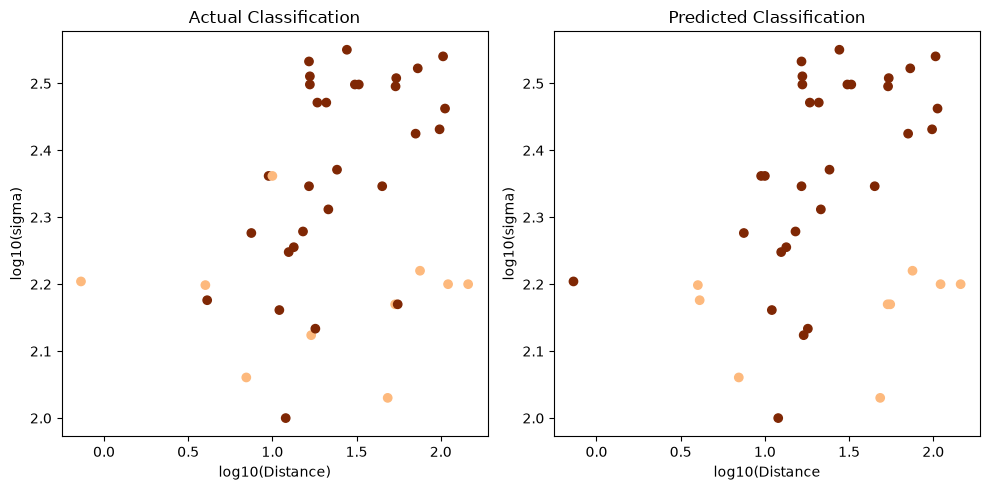

In [25]:
#Part4 continued
#create scatter plots
#use maximum accuracy given at depth 5
clf = DecisionTreeClassifier(random_state=0, max_depth=5, criterion='entropy')
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

plt.figure(figsize=(10,5))

#Actual
plt.subplot(1, 2, 1)
im = plt.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap=plt.cm.Oranges)
im.set_clim(-0.5, 1)
plt.xlabel('log10(Distance)')
plt.ylabel('log10(sigma)')
plt.title('Actual Classification')

#Predicted
plt.subplot(1, 2, 2)
im = plt.scatter(X_test[:,0], X_test[:,1], c=y_pred, cmap=plt.cm.Oranges)
im.set_clim(-0.5, 1)
plt.xlabel('log10(Distance')
plt.ylabel('log10(sigma)')
plt.title('Predicted Classification')

plt.tight_layout()
plt.show()

The highest classification accuracy was at a depth of 5. I wasn't able to achieve perfect accuracy but most of the samples were correctly classified.

C:\Users\itsya\anaconda3\envs\astr3300_3\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


Number of galaxies: 78
Alpha: 8.009500144334481
Beta: 2.089565144184271


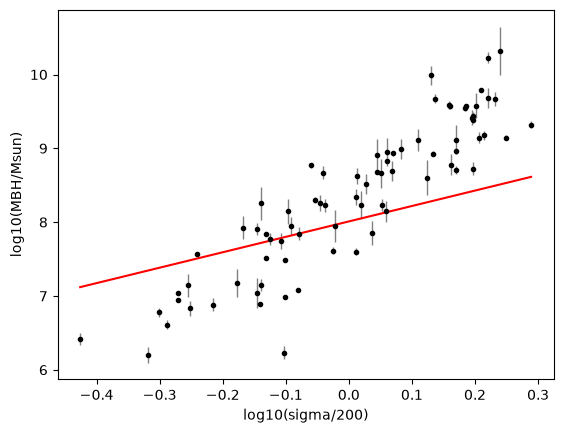

In [27]:
#Part5A
#linear regression is best for this case
from astroML.linear_model import LinearRegression

#Black hole
logMBH = np.log10(df['MBH'].values)
MBH_err = (df['MBH_upper'].values - df['MBH_lower'].values) / 2

#logarithmic uncertainty (I looked this formula up)
logMBH_err = MBH_err / (df['MBH'].values * np.log(10))

#independent variable
x_sigma = np.log10(df['sigma'].values / 200)
X_sigma = x_sigma[:,None]

#regression model
model = LinearRegression()
model.fit(X_sigma, logMBH, logMBH_err)

alpha = model.coef_[0]
beta = model.coef_[1]

print("Number of galaxies:", len(logMBH))
print("Alpha:", alpha)
print("Beta:", beta)

#Best fit
x_fit = np.linspace(min(x_sigma), max(x_sigma), 100)
y_fit = model.predict(x_fit[:,None])

plt.figure()
plt.errorbar(x_sigma, logMBH, logMBH_err, fmt='.k', ecolor='gray', lw=1)
plt.plot(x_fit, y_fit, '-r')
plt.xlabel('log10(sigma/200)')
plt.ylabel('log10(MBH/Msun)')
plt.show()

Number of galaxies: 48
Alpha: 9.440101141630555
Beta: 1.0246408325745706


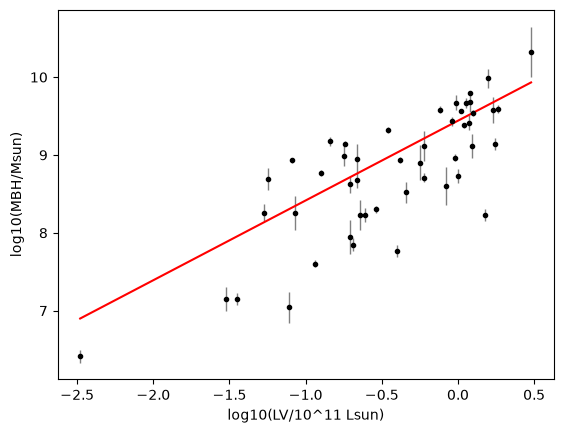

In [31]:
#Part5B
#select only galaxies with vband luminosity
mask = df['logLV'].values > 0

x_LV = df['logLV'].values[mask] - 11
X_LV = x_LV[:,None]

logMBH_LV = logMBH[mask]
logMBH_err_LV = logMBH_err[mask]

#linear regression
model = LinearRegression()
model.fit(X_LV, logMBH_LV, logMBH_err_LV)

alpha = model.coef_[0]
beta = model.coef_[1]

print("Number of galaxies:", len(logMBH_LV))
print("Alpha:", alpha)
print("Beta:", beta)

#Best fit
x_fit = np.linspace(min(x_LV), max(x_LV), 100)
y_fit = model.predict(x_fit[:,None])

plt.figure()
plt.errorbar(x_LV, logMBH_LV, logMBH_err_LV, fmt='.k', ecolor='gray', lw=1)
plt.plot(x_fit, y_fit, '-r')
plt.xlabel('log10(LV/10^11 Lsun)')
plt.ylabel('log10(MBH/Msun)')
plt.show()

Number of galaxies: 38
Alpha: 8.57163135459361
Beta: 0.956645584408492


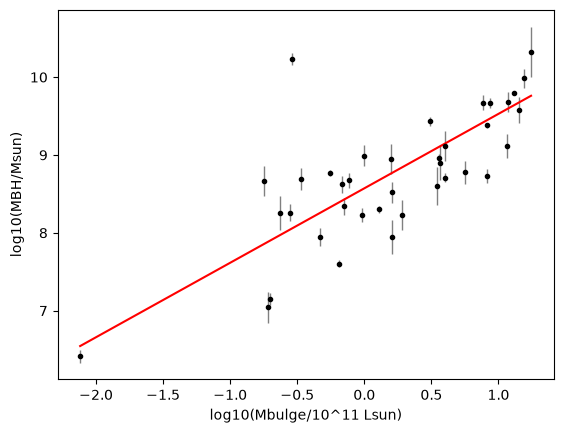

In [35]:
#Part5C
#initial code copied from 5B
#filter for galaxies with bulge mass
mask = df['Mbulge'].values > 0

x_bulge = np.log10(df['Mbulge'].values[mask] / 10**11)
X_bulge = x_bulge[:,None]

logMBH_bulge = logMBH[mask]
logMBH_err_bulge = logMBH_err[mask]

#linear regression
model = LinearRegression()
model.fit(X_bulge, logMBH_bulge, logMBH_err_bulge)

alpha = model.coef_[0]
beta = model.coef_[1]

print("Number of galaxies:", len(logMBH_bulge))
print("Alpha:", alpha)
print("Beta:", beta)

#Best fit
x_fit = np.linspace(min(x_bulge), max(x_bulge), 100)
y_fit = model.predict(x_fit[:,None])

plt.figure()
plt.errorbar(x_bulge, logMBH_bulge, logMBH_err_bulge, fmt='.k', ecolor='gray', lw=1)
plt.plot(x_fit, y_fit, '-r')
plt.xlabel('log10(Mbulge/10^11 Lsun)')
plt.ylabel('log10(MBH/Msun)')
plt.show()

Degree: 0
Coeffs: [7.55713015]
BIC: 82216.64274592255
Degree: 1
Coeffs: [8.00950014 2.08956514]
BIC: 62899.70536158146
Degree: 2
Coeffs: [ 7.69038155  5.28406501 19.3794119 ]
BIC: 27907.26275916175
Degree: 3
Coeffs: [  7.83095985   6.79897196  14.77832274 -35.1382254 ]
BIC: 26604.764351585287
Degree: 4
Coeffs: [   7.79503705    9.45048813   34.57786632  -94.60518792 -385.1907937 ]
BIC: 17568.132018031836
Degree: 5
Coeffs: [   7.87203268    9.90857248   27.44118815 -120.94602857 -285.9383216
  313.71867932]
BIC: 17352.94070242882


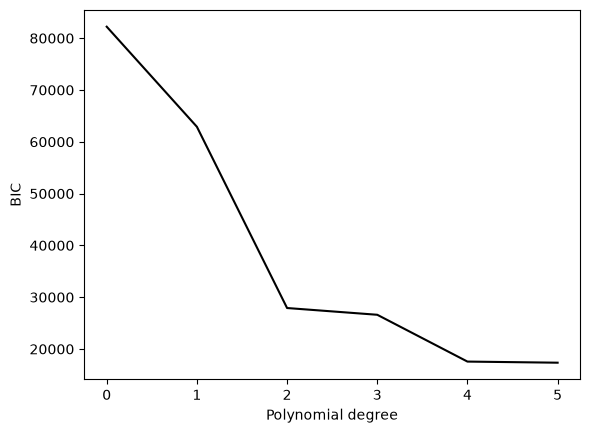

In [42]:
#Part6
from astroML.linear_model import PolynomialRegression

degrees = np.arange(0,6)
BIC = np.zeros(len(degrees))
N = len(logMBH)

for degree in degrees:
    model = PolynomialRegression(degree)
    model.fit(X_sigma, logMBH, logMBH_err)

    y_pred = model.predict(X_sigma)
    n_constraints = degree + 1
    logL = -0.5 *np.sum(((logMBH - y_pred) / logMBH_err)**2 + np.log(2 * np.pi * logMBH_err**2))
    BIC[degree] = n_constraints * np.log(N) -2 *logL

    print("Degree:", degree)
    print("Coeffs:", model.coef_)
    print("BIC:", BIC[degree])

plt.figure()
plt.plot(degrees, BIC, '-k')
plt.xlabel('Polynomial degree')
plt.ylabel('BIC')
plt.show()

In [ ]:
#Part7
#separare early and late type galaxies
early = y ==1
late = y ==0

#regression
model_all = LinearRegression()
model_all.fit(X_sigma, logMBH, logMBH_err)

#early regression
model_early = LinearRegression()
model_early.fit(X_sigma[early], logMNH[early], logMBH_err[early])

#late regression
model_late = LinearRegression()
model_late.fit(X_sigma[late], logMNH[late], logMBH_err[late])

print("Early type galaxies:", len(logMBH[early]))
print("Coeffs:", model_early.coef_)

print("Late type galaxies:", len(logMBH[late]))
print("Coeffs:", model_late.coef_)

#Best fit
x_fit = np.linspace(min(x_sigma), max(x_sigma), 100)
y_fit_all = model.all.predict(x_fit[:,None])
y_fit_early = model.early.predict(x_fit[:,None])
y_fit_late = model.late.predict(x_fit[:,None])

